# PHYS 142/242 — Assignment 2: Tunneling in the Double Potential Well

**Name:** Ken Nguyen

**TSN:**  200288141

**My $\alpha$:** $\alpha = 0.3 + d/5000$ where $d$ = last three digits of TSN → $\alpha =$  


### How to use this notebook in VS Code
- **Pick the kernel first:** **Select Kernel** (top right) → *Python Environments* → your `.venv`.
- **Run a cell:** `Shift+Enter` runs it and moves on. `Ctrl+Enter` runs it and stays.
- **Add a cell:** hover between cells → **+ Code** / **+ Markdown**.
- **Switch cell type:** `Esc`, then `M` (Markdown) or `Y` (code).
- **Run top to bottom.** If things act strangely: **Restart**, then **Run All**.
- **Order tip:** the code runs A → B → C → D, but A(ii) compares with D's curve. Write the A(ii) answer after you've finished D.

## 0. Environment check
Run once. Every line should print a version number, not `MISSING`.

In [2]:
import sys, importlib
print("Python", sys.version.split()[0], "at", sys.executable)
for pkg in ["numpy", "scipy", "matplotlib", "numba"]:
    try:
        print(f"{pkg:<11}", importlib.import_module(pkg).__version__)
    except ImportError:
        print(f"{pkg:<11} MISSING")

Python 3.12.10 at c:\Users\Admin\OneDrive\Desktop\PHYS242\.venv\Scripts\python.exe
numpy       2.5.4
scipy       1.18.1
matplotlib  3.11.2
numba       0.68.1


## Setup

**Numerical conventions (from the assignment):**
- Grid: $N_D+1 = 601$ points from $x_0=-4$ to $x_{N_D}=4$, $N_D=600$, $\Delta x = 8/600$. Only B(ii) changes the grid.
- Time step: $\epsilon = \Delta t = \pi/128$.
- Integrals: $\int f(x)\,dx \approx \Delta x \sum_{i=0}^{N_D} f(x_i)$, **including both endpoints**.
- $t_\text{tunnel}$: time of the first **major** minimum of $\langle x\rangle(t)$ (not a zero crossing, not a small wiggle).
- Units: $m=\hbar=1$.

**Potential and harmonic approximation:**
$$V(x)=\alpha x^4-2x^2+\frac1\alpha,\qquad x_\text{min}=\frac{1}{\sqrt\alpha},\qquad V_\pm(x)=4(x\mp x_\text{min})^2,\qquad \omega=2\sqrt2$$
$$\psi_\pm(x)=\left(\frac{\omega}{\pi}\right)^{1/4}\exp\!\left[-\frac{\omega}{2}(x\mp x_\text{min})^2\right],\qquad
\psi_S=\frac{\psi_++\psi_-}{\sqrt2},\quad \psi_A=\frac{\psi_+-\psi_-}{\sqrt2}$$

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse
import scipy.sparse.linalg
from numba import njit

In [4]:
# Constants: TSN, ALPHA, grid (ND, x, DELTAX), time step (DELTAT), OMEGA, XMIN
TSN = '200288141'
d = int(TSN[-3:])
ALPHA = 0.3 + d / 5000

#reduced units
HBAR = 1.0
MASS = 1.0

#spatial grid which is used for JSON results
BOXSIZE = 8.0 # for interval [-4,4]
ND = 600 # number of intervals
DELTAX = BOXSIZE / ND
x = np.linspace(-BOXSIZE / 2, BOXSIZE / 2, ND + 1) #601 points for both endpoints included

# time step
DELTAT = np.pi / 128

# harmonic approximation
XMIN = 1 / np.sqrt(ALPHA)
OMEGA = 2 * np.sqrt(2)

# export times 
N_EXPORT = np.arange(0, 2049, 64)
print(f"alpha = {ALPHA}, x_min = {XMIN:.6f}, barrier V(0) = {1/ALPHA:.6f}")
print(f"grid: {x.size} points, dx = {DELTAX:.6f}, x[1]-x[0] = {x[1]-x[0]:.6f}")
print(f"dt = {DELTAT:.6f}, export steps: {N_EXPORT.size} values, last t = {N_EXPORT[-1]*DELTAT:.4f}")

alpha = 0.3282, x_min = 1.745544, barrier V(0) = 3.046923
grid: 601 points, dx = 0.013333, x[1]-x[0] = 0.013333
dt = 0.024544, export steps: 33 values, last t = 50.2655


In [5]:
# Shared functions: V(x, alpha), psi_plus / psi_minus, ...

@njit
def V(x, alpha):
    """Double-well potential, eq. (1). @njit so the path-integral kernel can call it later."""
    return alpha * x**4 - 2 * x**2 + 1 / alpha

def V_plus(x, xmin):
    """Harmonic approximation around the right minimum, eq. (3)."""
    return 4 * (x - xmin)**2

def V_minus(x, xmin):
    """Harmonic approximation around the left minimum, eq. (4)."""
    return 4 * (x + xmin)**2

def gaussian_ground_state(x, center):
    """Harmonic-oscillator ground state centered at `center`, eq. (5)."""
    return (OMEGA / (np.pi * HBAR))**0.25 * np.exp(-OMEGA * (x - center)**2 / (2 * HBAR))

def integrate(f):
    """Grid integral: dx * sum over ALL points, including both endpoints (assignment convention)."""
    return DELTAX * np.sum(f)

def normalize(psi):
    """Return psi / sqrt( integral |psi|^2 dx )."""
    return psi / np.sqrt(integrate(np.abs(psi)**2))

# Localized states in each well
psi_plus = gaussian_ground_state(x, +XMIN)    # right well, the initial state for Problem A
psi_minus = gaussian_ground_state(x, -XMIN)   # left well


In [6]:
## Sanity Checks
print("V(+xmin), V(-xmin):", V(XMIN, ALPHA), V(-XMIN, ALPHA))      # both should be 0
print("V(0) vs 1/alpha:   ", V(0.0, ALPHA), 1 / ALPHA)
h = 1e-4
print("V''(xmin) numeric: ", (V(XMIN + h, ALPHA) - 2 * V(XMIN, ALPHA) + V(XMIN - h, ALPHA)) / h**2)   # should be ~8
print("norm of psi_plus:  ", integrate(np.abs(psi_plus)**2))        # should be ~1

V(+xmin), V(-xmin): 4.440892098500626e-16 4.440892098500626e-16
V(0) vs 1/alpha:    3.0469226081657528 3.0469226081657528
V''(xmin) numeric:  7.999999951380232
norm of psi_plus:   0.9999999623646078


---
## Problem A [10 pts]: Path-integral tunneling

Start in the right well, $\psi(x,0)=\psi_+(x)$. Propagate one step at a time with the **midpoint** short-time kernel
$$\tilde K(x_b,\epsilon;x_a,0)=\exp\left[i\left(\frac12\frac{(x_b-x_a)^2}{\epsilon}-V\!\left(\frac{x_a+x_b}{2}\right)\epsilon\right)\right]$$
and normalize after **every** step: $\psi \leftarrow \psi/\sqrt{\int|\psi|^2dx}$.

For `results.json`: run to **at least $16\pi$** (2048 steps), longer if needed to see a full oscillation. Save $\langle x\rangle$ at $n = 0, 64, 128, \dots, 2048$.

### Analysis of Problem A: path-integral propagation in the double well

### A.1 Goal
The particle starts localized in the right well,
$$
\psi(x,0)=\psi_+(x)=\left(\frac{\omega}{\pi}\right)^{1/4}e^{-\frac{\omega}{2}(x-x_{\min})^2},\qquad \omega=2\sqrt2,\quad x_{\min}=\frac{1}{\sqrt\alpha},
$$
and we follow it in time without solving for any eigenstates, using only the path-integral propagator. The observable is the mean position
$$
\langle x\rangle(t)=\int x\,|\psi(x,t)|^2\,dx ,
$$
and from it the tunneling time $t_\text{tunnel}$: the time of the first **major** minimum of $\langle x\rangle(t)$.

### A.2 Time evolution with a propagator
For a time-independent Hamiltonian, the state at a later time is obtained by integrating against the propagator:
$$
\psi(x_b,t+\epsilon)=\int K(x_b,\epsilon;\,x_a,0)\,\psi(x_a,t)\,dx_a,
\qquad
K(x_b,\epsilon;\,x_a,0)=\langle x_b|\,e^{-i\hat H\epsilon/\hbar}\,|x_a\rangle .
$$
$K$ depends only on the step length $\epsilon$, not on $t$, so the **same** kernel advances the state at every step. Repeating the step $n$ times gives $\psi(x,n\epsilon)$.

### A.3 The short-time kernel
For a short step, the dominant path from $x_a$ to $x_b$ is a straight line with velocity $v=(x_b-x_a)/\epsilon$. Its classical action is
$$
S=\int_0^{\epsilon}\left[\tfrac12 m\dot x^2-V(x)\right]dt
\;\approx\;\frac{m(x_b-x_a)^2}{2\epsilon}-\epsilon\,V\!\left(\frac{x_a+x_b}{2}\right),
$$
where $\int V\,dt$ is approximated by the **midpoint rule**. The short-time propagator is $K\approx A\,e^{iS/\hbar}$ with $A=\sqrt{m/(2\pi i\hbar\epsilon)}$. With $m=\hbar=1$ and $A$ omitted:
$$
\boxed{\;\tilde K(x_b,\epsilon;x_a,0)=\exp\left[i\left(\frac{(x_b-x_a)^2}{2\epsilon}-V\!\left(\frac{x_a+x_b}{2}\right)\epsilon\right)\right]\;}
$$
The first term is the free-particle (kinetic) phase; the second is the phase accumulated from the potential during the step.

### A.4 Why the prefactor can be dropped: normalization
$A$ is a constant: it does not depend on $x_a$, $x_b$ or $t$. Omitting it rescales $\psi$ by the same factor at every point, which leaves its shape and relative phases unchanged. Normalizing after every step removes that factor:
$$
\psi(x,t)\;\leftarrow\;\frac{\psi(x,t)}{\sqrt{\int|\psi(x,t)|^2\,dx}} .
$$
This is needed regardless, because evolution on a finite grid and box is not exactly unitary.

### A.5 Discretization: the kernel matrix
On the grid $x_i=-4+i\,\Delta x$ ($i=0,\dots,N_D$) with $\int f\,dx\approx\Delta x\sum_{i=0}^{N_D}f(x_i)$, the integral in A.2 becomes a matrix–vector product:
$$
\psi_i(t+\epsilon)=\Delta x\sum_{j=0}^{N_D}\tilde K_{ij}\,\psi_j(t),
\qquad
\tilde K_{ij}\equiv\tilde K(x_i,\epsilon;\,x_j,0).
$$
Row $i$ is the arrival point $x_b=x_i$; column $j$ is the starting point $x_a=x_j$.

**Factorized form.** Using $x_i-x_j=(i-j)\Delta x$ and $\tfrac{x_i+x_j}{2}=x_{(i+j)/2}$:
$$
\tilde K_{ij}=\underbrace{e^{\,i\kappa\,(i-j)^2}}_{\text{kinetic: depends on }i-j}\cdot\underbrace{e^{-i\epsilon V\left(x_{(i+j)/2}\right)}}_{\text{potential: depends on }i+j},
\qquad
\kappa\equiv\frac{\Delta x^2}{2\epsilon}\approx3.62\times10^{-3}.
$$
$x_{(i+j)/2}$ is a grid point when $i+j$ is even and lies halfway between grid points when $i+j$ is odd.

Define two sets of phases, each indexed by a single integer:
$$
p_k\equiv e^{\,i\kappa k^2}\quad(k=|i-j|=0,1,\dots,N_D),
\qquad
q_s\equiv e^{-i\epsilon\,V\left(x_{s/2}\right)}\quad(s=i+j=0,1,\dots,2N_D),
$$
where $\kappa=\Delta x^2/(2\epsilon)$ and $x_{s/2}=x_0+\tfrac{s}{2}\Delta x$ is the midpoint of $x_i$ and $x_j$. Note that $p_0=1$.

Every entry is then one kinetic phase times one potential phase:
$$
\tilde K_{ij}=p_{|i-j|}\;q_{i+j}.
$$

**Full $(N_D+1)\times(N_D+1)$ matrix** (rows $i=0\dots N_D$ = arrival point $x_b$, columns $j=0\dots N_D$ = starting point $x_a$):
$$
\tilde K=
\begin{pmatrix}
q_0 & p_1q_1 & p_2q_2 & p_3q_3 & \cdots & p_{N_D}q_{N_D}\\
p_1q_1 & q_2 & p_1q_3 & p_2q_4 & \cdots & p_{N_D-1}q_{N_D+1}\\
p_2q_2 & p_1q_3 & q_4 & p_1q_5 & \cdots & p_{N_D-2}q_{N_D+2}\\
p_3q_3 & p_2q_4 & p_1q_5 & q_6 & \cdots & p_{N_D-3}q_{N_D+3}\\
\vdots & \vdots & \vdots & \vdots & \ddots & \vdots\\
p_{N_D}q_{N_D} & p_{N_D-1}q_{N_D+1} & p_{N_D-2}q_{N_D+2} & p_{N_D-3}q_{N_D+3} & \cdots & q_{2N_D}
\end{pmatrix}
$$

The matrix is symmetric since $\tilde K_{ij}=\tilde K_{ji}$ ($(i-j)^2$ and $i+j$ are unchanged by swapping). It is complex symmetric, **not** Hermitian.

What to expect: the eigenstate picture
Expand the initial state in the (real) energy eigenstates, $\psi_+=\sum_n c_n\phi_n$ with $c_n=\int\phi_n\psi_+\,dx$. Each component only acquires a phase, so
$$
\psi(x,t)=\sum_n c_n e^{-iE_nt/\hbar}\phi_n(x)
\;\Rightarrow\;
\langle x\rangle(t)=\sum_{m,n}c_mc_n\,x_{mn}\cos\!\left(\frac{(E_n-E_m)\,t}{\hbar}\right),
\qquad
x_{mn}=\int\phi_m\,x\,\phi_n\,dx .
$$

### A(i) Run and plot
Follow one full slow oscillation (right → left → back). Plot $\langle x\rangle(t)$ and **mark the measured $t_\text{tunnel}$**. Use $2\pi/\Delta E$ from B to choose the run length, but do **not** substitute $\pi/\Delta E$ for the measured time.

In [7]:
# A(i): build kernel, evolve psi_+, compute <x>(t), find t_tunnel, plot

@njit
def build_kernel(x, dt, alpha):
    """Kernel matrix K~_ij = exp{ i[ (x_i - x_j)^2 / (2 dt) - V((x_i + x_j)/2) dt ] }   (theory A.5)
    Row i = arrival point x_b = x_i, column j = starting point x_a = x_j."""
    n = x.size
    K = np.empty((n, n), dtype=np.complex128)
    for i in range(n):
        for j in range(n):
            kinetic = 0.5 * (x[i] - x[j])**2 / dt              # free-particle phase
            potential = V(0.5 * (x[i] + x[j]), alpha) * dt      # midpoint potential phase
            K[i, j] = np.exp(1j * (kinetic - potential))
    return K

@njit
def evolve(psi0, K, dx, nt):
    """Path-integral evolution (theory A.6): nt steps of psi <- dx K psi, renormalized every step.
    Returns the probability density prob[n, i] = |psi(x_i, n*dt)|^2 for n = 0, ..., nt."""
    psi = psi0.astype(np.complex128)
    psi = psi / np.sqrt(dx * np.sum(np.abs(psi)**2))     # normalize the initial state on the grid
    prob = np.empty((nt + 1, psi.size))
    prob[0] = np.abs(psi)**2
    for n in range(nt):
        psi = dx * (K @ psi)                              # one step: matrix-vector product
        psi = psi / np.sqrt(dx * np.sum(np.abs(psi)**2))  # renormalize (prefactor was dropped)
        prob[n + 1] = np.abs(psi)**2
    return prob

# --- build the kernel once (first call also compiles, so it takes a few seconds) ---
K_tilde = build_kernel(x, DELTAT, ALPHA)
print("K~ shape:", K_tilde.shape)
print("symmetric (K = K^T):", np.allclose(K_tilde, K_tilde.T))
print("max | |K_ij| - 1 |:", np.max(np.abs(np.abs(K_tilde) - 1)))

# --- run length: >= 16*pi (results.json) AND >= one full slow period 2*pi/dE ---
# A look ahead at Problem B gives dE ~ 0.048, so 2*pi/dE ~ 132. 48*pi ~ 151 covers one full
# oscillation but stops before the second left minimum (~3*pi/dE ~ 198). Re-check after B.
T_RUN = 48 * np.pi
NT = int(np.ceil(T_RUN / DELTAT))
t = np.arange(NT + 1) * DELTAT

prob_A = evolve(psi_plus, K_tilde, DELTAX, NT)
x_mean_A = DELTAX * (prob_A @ x)                       # <x>(t) = dx * sum_i x_i |psi_i|^2

# --- tunneling time: first MAJOR minimum = deepest point of <x> in the first slow oscillation ---
# (not the first zero crossing: the fast wiggles make <x> cross zero several times)
n_tunnel = np.argmin(x_mean_A)
t_tunnel = t[n_tunnel]

# --- values for results.json: <x> at n = 0, 64, ..., 2048 ---
x_mean_pi = x_mean_A[N_EXPORT]

print(f"steps: {NT}, run to t = {t[-1]:.3f}")
print(f"<x>(0) = {x_mean_A[0]:.6f}  (x_min = {XMIN:.6f})")
print(f"t_tunnel = {t_tunnel:.4f}  (step n = {n_tunnel}),  <x>(t_tunnel) = {x_mean_A[n_tunnel]:.4f}")

K~ shape: (601, 601)
symmetric (K = K^T): True
max | |K_ij| - 1 |: 2.220446049250313e-16
steps: 6144, run to t = 150.796
<x>(0) = 1.745544  (x_min = 1.745544)
t_tunnel = 63.9609  (step n = 2606),  <x>(t_tunnel) = -1.7171


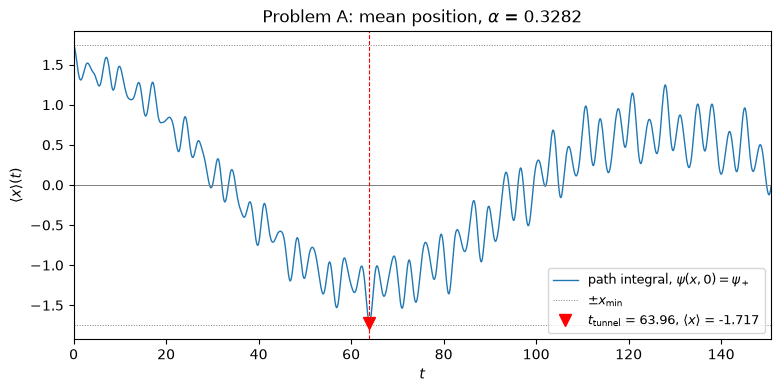

In [8]:
# A(i): plot <x>(t) with t_tunnel marked

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, x_mean_A, lw=1, label=r"path integral, $\psi(x,0)=\psi_+$")
ax.axhline(0, color="gray", lw=0.7)
ax.axhline(+XMIN, color="gray", lw=0.7, ls=":")
ax.axhline(-XMIN, color="gray", lw=0.7, ls=":", label=r"$\pm x_\mathrm{min}$")
ax.axvline(t_tunnel, color="red", lw=0.8, ls="--")
ax.plot(t_tunnel, x_mean_A[n_tunnel], "v", color="red", ms=9,
        label=rf"$t_\mathrm{{tunnel}}$ = {t_tunnel:.2f}, $\langle x\rangle$ = {x_mean_A[n_tunnel]:.3f}")
ax.set(xlabel=r"$t$", ylabel=r"$\langle x\rangle(t)$", xlim=(0, t[-1]),
       title=rf"Problem A: mean position, $\alpha$ = {ALPHA}")
ax.legend(loc="lower right", fontsize=9)
plt.show()

|c0|^2 = 0.4652, |c1|^2 = 0.4820, two-state fraction = 0.9472  -> 5.28% in higher states
fast angular frequency = 1.833  ->  period = 3.43   (slow: dE = 0.0477, period 2pi/dE = 131.7)


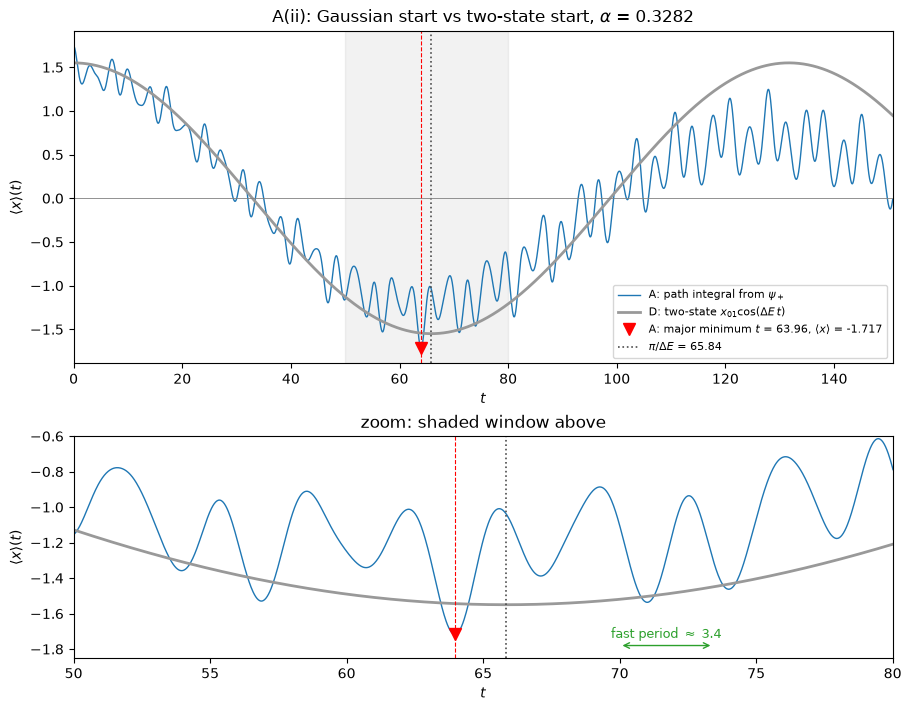

In [27]:
# ---------- A(ii): read the result, using D's two-state curve as the reference ----------
# 1. how much of psi_+ is in the two lowest states? (the rest is higher states)
psi_p_n = normalize(psi_plus)
c0, c1 = integrate(phi0 * psi_p_n), integrate(phi1 * psi_p_n)
print(f"|c0|^2 = {c0**2:.4f}, |c1|^2 = {c1**2:.4f}, two-state fraction = {c0**2 + c1**2:.4f}  "
      f"-> {1 - c0**2 - c1**2:.2%} in higher states")

# 2. period of the fast fluctuation: strongest spectral peak of A's <x>(t) well above the slow frequency
spec = np.abs(np.fft.rfft(x_mean_A - x_mean_A.mean()))
freq = 2 * np.pi * np.fft.rfftfreq(x_mean_A.size, DELTAT)           # angular frequency
fast = freq > 10 * DELTA_E                                           # skip the slow tunneling peak
w_fast = freq[fast][np.argmax(spec[fast])]
print(f"fast angular frequency = {w_fast:.3f}  ->  period = {2 * np.pi / w_fast:.2f}"
      f"   (slow: dE = {DELTA_E:.4f}, period 2pi/dE = {2 * np.pi / DELTA_E:.1f})")

# 3. A vs D: same path-integral code, different initial state (full run + zoom on the minimum)
fig, (ax, az) = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw={"height_ratios": [3, 2]}, constrained_layout=True)
for a_ in (ax, az):
    a_.plot(t, x_mean_A, lw=1, color="C0", label=r"A: path integral from $\psi_+$")
    a_.plot(t, x01 * np.cos(DELTA_E * t), lw=2, color="0.6", label=r"D: two-state $x_{01}\cos(\Delta E\,t)$")
    a_.axvline(t_tunnel, color="red", ls="--", lw=0.8)
    a_.plot(t_tunnel, x_mean_A[n_tunnel], "v", color="red", ms=9,
            label=rf"A: major minimum $t$ = {t_tunnel:.2f}, $\langle x\rangle$ = {x_mean_A[n_tunnel]:.3f}")
    a_.axvline(np.pi / DELTA_E, color="0.3", ls=":", lw=1.2, label=rf"$\pi/\Delta E$ = {np.pi / DELTA_E:.2f}")
    a_.axhline(0, color="gray", lw=0.6)
    a_.set(xlabel=r"$t$", ylabel=r"$\langle x\rangle(t)$")
ax.set(xlim=(0, t[-1]), title=rf"A(ii): Gaussian start vs two-state start, $\alpha$ = {ALPHA}")
ax.legend(loc="lower right", fontsize=8)
ax.axvspan(50, 80, color="gray", alpha=0.1)                       # region shown in the zoom

az.set(xlim=(50, 80), ylim=(-1.85, -0.6), title="zoom: shaded window above")
P = 2 * np.pi / w_fast                                            # mark one fast period
az.annotate("", xy=(70 + P, -1.78), xytext=(70, -1.78), arrowprops=dict(arrowstyle="<->", color="C2"))
az.text(70 + P / 2, -1.74, rf"fast period $\approx$ {P:.1f}", color="C2", ha="center", fontsize=9)
plt.show()

### A(ii) 

+ $t_\text{tunnel}=63.96$, $\langle x\rangle=-1.717$, versus $\pi/\Delta E=65.84$ and $-x_{01}=-1.550$ for the two-state curve.
+ wiggles with period $\approx3.4$ (angular frequency $1.83$), about $40\times$ faster than the slow transfer (period $2\pi/\Delta E\approx132$). The slow part is the $\phi_0$–$\phi_1$ tunneling; the wiggles are beats with higher states.
+ D's curve is a single sinusoid, whereas A's minimum is earlier and deeper, it carries large wiggles, and it does not return fully. Only $94.7\%$ of $\psi_+$ is in $\phi_0,\phi_1$; the other $5.3\%$ is in higher states.
+ * A's wiggles are large ($\sim0.3$) **from $t=0$**. D, run with the **same** path-integral code, deviates from a sinusoid by at most $0.075$, and that deviation only grows slowly from zero. So A's departures come from its initial state containing higher states, not from numerical error. The minimum sits where a fast wiggle's low point coincides with the slow minimum, which shifts it from $\pi/\Delta E$.

---
## Problem B [10 pts]: Numerical eigenstates

Find $E_0, E_1$ and $\phi_0,\phi_1$ of $\hat H=-\frac12\partial_x^2+V(x)$ with the $(N_D+1)\times(N_D+1)$ three-point matrix
$$H_{ii}=\frac{1}{\Delta x^2}+V(x_i),\qquad H_{i,i+1}=H_{i+1,i}=-\frac{1}{2\Delta x^2}.$$
- **Endpoints:** keep all $N_D+1$ points. Just drop the outside neighbor in the first and last rows.
- **Solver:** `scipy.sparse.linalg.eigsh(H, k=2, sigma=0, which="LM")` (shift-invert), as in the Lecture 11 demo.

### Analysis of Problem B

### B.1 Goal
Solve the time-independent Schrödinger equation ($m=\hbar=1$)
$$
\hat H\phi_n(x)=-\frac12\frac{d^2\phi_n}{dx^2}+V(x)\,\phi_n(x)=E_n\,\phi_n(x),\qquad V(x)=\alpha x^4-2x^2+\frac1\alpha,
$$
for the two lowest states $(E_0,\phi_0)$ and $(E_1,\phi_1)$. Everything later depends on them: $\Delta E=E_1-E_0$ sets the tunneling time scale (A, D), C compares the harmonic estimates against them, and D builds its initial state from $\phi_0,\phi_1$.

### B.2 Discretizing the second derivative
On the grid $x_i=x_0+i\,\Delta x$, Taylor-expand $\phi(x_i\pm\Delta x)$:
$$
\phi_{i\pm1}=\phi_i\pm\Delta x\,\phi_i'+\frac{\Delta x^2}{2}\phi_i''\pm\frac{\Delta x^3}{6}\phi_i'''+\frac{\Delta x^4}{24}\phi_i''''+\dots
$$
Adding the two expansions cancels the odd terms:
$$
\frac{\phi_{i+1}-2\phi_i+\phi_{i-1}}{\Delta x^2}=\phi_i''+\frac{\Delta x^2}{12}\phi_i''''+\mathcal O(\Delta x^4).
$$
The **centered three-point formula** is therefore second-order accurate: its error scales as $\Delta x^2$.

### B.3 The Hamiltonian matrix
Substituting into the Schrödinger equation at each grid point gives
$$
-\frac{1}{2\Delta x^2}\left(\phi_{i+1}-2\phi_i+\phi_{i-1}\right)+V(x_i)\,\phi_i=E\,\phi_i ,
$$
i.e. a matrix eigenvalue problem $H\boldsymbol\phi=E\boldsymbol\phi$ with
$$
H_{ii}=\frac{1}{\Delta x^2}+V(x_i)\equiv d_i,\qquad H_{i,i\pm1}=-\frac{1}{2\Delta x^2}\equiv-\tau,\qquad\text{all other entries }0.
$$
Written out, it is $(N_D+1)\times(N_D+1)$ and **tridiagonal**:
$$
H=\begin{pmatrix}
d_0 & -\tau & & & & \\
-\tau & d_1 & -\tau & & & \\
 & -\tau & d_2 & -\tau & & \\
 & & \ddots & \ddots & \ddots & \\
 & & & -\tau & d_{N_D-1} & -\tau\\
 & & & & -\tau & d_{N_D}
\end{pmatrix},
\qquad
\begin{pmatrix}\phi_0\\ \phi_1\\ \phi_2\\ \vdots\\ \phi_{N_D-1}\\ \phi_{N_D}\end{pmatrix}=\boldsymbol\phi .
$$
It splits into a kinetic part (independent of $\alpha$) and a diagonal potential part:
$$
H=\underbrace{\frac{1}{2\Delta x^2}\begin{pmatrix}
2 & -1 & & \\
-1 & 2 & -1 & \\
 & \ddots & \ddots & \ddots\\
 & & -1 & 2
\end{pmatrix}}_{T\;=\;-\frac12\,\frac{d^2}{dx^2}}
+\underbrace{\begin{pmatrix}
V(x_0) & & & \\
 & V(x_1) & & \\
 & & \ddots & \\
 & & & V(x_{N_D})
\end{pmatrix}}_{\text{diag}(V)}.
$$
On the original grid ($\Delta x=8/600$): $1/\Delta x^2=5625$ and $\tau=2812.5$.

### B.4 Boundary conditions
All $N_D+1$ points are kept as unknowns, and the outside neighbor is simply omitted in the first and last rows. Row $0$ reads
$$
-\tau\,\phi_1+d_0\,\phi_0=E\,\phi_0
\quad\Longleftrightarrow\quad
-\frac{1}{2\Delta x^2}\left(\phi_1-2\phi_0+\underbrace{\phi_{-1}}_{=\,0}\right)+V(x_0)\phi_0=E\phi_0 .
$$
So the matrix imposes $\phi=0$ at the **ghost points** $x_{-1}=x_0-\Delta x$ and $x_{N_D+1}=x_{N_D}+\Delta x$, i.e. hard walls just *outside* the box, not at $x_0,x_{N_D}$ themselves.

The solver: shift-invert
Iterative (Krylov/ARPACK) methods converge fastest to eigenvalues of **largest magnitude** that are well separated from the rest. Asking for the smallest, `which="SM"`, is slow here: on a scale of $\sim10^4$, $E_0$ and $E_1$ are bunched near zero.

**Shift-invert** turns the problem around. For a shift $\sigma$:
$$
H\boldsymbol\phi_n=E_n\boldsymbol\phi_n
\;\Longleftrightarrow\;
(H-\sigma I)^{-1}\boldsymbol\phi_n=\frac{1}{E_n-\sigma}\,\boldsymbol\phi_n .
$$
Same eigenvectors, and the eigenvalues closest to $\sigma$ become the **largest** in magnitude. With $\sigma=0$ (allowed because all $E_n>0$, B.5), the two lowest states become the two dominant ones. A harmonic estimate gives the lowest doublet at $\approx\omega/2=\sqrt2\approx1.4$ and the next at $\approx3\omega/2\approx4.2$, so the mapped values are $\approx0.7$ versus $\approx0.24$: a separation of about $3\times$, which converges in a few iterations.

**Inverse power iteration** (the idea behind it): start from a random $\boldsymbol u_0$ and repeat
$$
(H-\sigma I)\,\boldsymbol u_{k+1}=\boldsymbol u_k,\qquad \boldsymbol u_{k+1}\leftarrow\frac{\boldsymbol u_{k+1}}{\|\boldsymbol u_{k+1}\|}.
$$
The component along $\boldsymbol\phi_n$ grows like $(E_n-\sigma)^{-k}$, so the state closest to $\sigma$ dominates. `eigsh(H, k=2, sigma=0, which="LM")` does a more refined version (Lanczos) that returns both $\phi_0$ and $\phi_1$.

**Never form the inverse.** $(H-\sigma I)^{-1}$ is dense. Instead, factor the tridiagonal matrix once as $H-\sigma I=LU$ with bidiagonal factors
$$
L=\begin{pmatrix}
1 & & & \\
\ell_1 & 1 & & \\
 & \ddots & \ddots & \\
 & & \ell_{N_D} & 1
\end{pmatrix},
\qquad
U=\begin{pmatrix}
u_0 & -\tau & & \\
 & u_1 & -\tau & \\
 & & \ddots & \ddots\\
 & & & u_{N_D}
\end{pmatrix},
$$
$$
u_0=d_0-\sigma,\qquad \ell_i=-\frac{\tau}{u_{i-1}},\qquad u_i=d_i-\sigma-\frac{\tau^2}{u_{i-1}} .
$$
Each iteration then solves $L\boldsymbol y=\boldsymbol u_k$ (forward substitution) and $U\boldsymbol u_{k+1}=\boldsymbol y$ (back substitution), costing only $\mathcal O(N_D)$.

### B.5 From eigenvectors to wave functions
The solver returns unit vectors, $\sum_i|v_i|^2=1$. A wave function needs $\int|\phi|^2dx\approx\Delta x\sum_i|\phi_i|^2=1$, so
$$
\phi_i=\frac{v_i}{\sqrt{\Delta x}}\quad\Rightarrow\quad\Delta x\sum_i|\phi_i|^2=\Delta x\cdot\frac{1}{\Delta x}\sum_i|v_i|^2=1 .
$$
The overall sign of an eigenvector is arbitrary (the solver starts from a random vector), so the convention is fixed by hand: **$\phi_0>0$** everywhere, and **the right-hand lobe of $\phi_1$ positive** ($\phi_1(x)>0$ for $x>0$). This matters for D's initial state $(\phi_0+\phi_1)/\sqrt2$, which then sits in the **right** well, and for `results.json`.

### B.6 Validation against Banerjee & Bhatnagar (B(i))
Their potential uses $\lambda=\alpha/4$, so $\alpha=0.4\leftrightarrow\lambda=0.10$ and $\alpha=0.6\leftrightarrow\lambda=0.15$.

**Expected size of our errors**
- **Grid spacing.** From B.2, the discrete kinetic energy is off by $-\frac{\Delta x^2}{24}\phi''''$. First-order perturbation theory gives $\delta E_n\approx-\frac{\Delta x^2}{24}\langle p^4\rangle_n$. In the harmonic approximation $\langle p^4\rangle_0=3\left(\frac{\omega}{2}\right)^2=6$, so
$$
\delta E\approx-\frac{(8/600)^2}{24}\cdot6\approx-4\times10^{-5}.
$$
This predicts that our energies come out slightly **too low**, at the $10^{-5}$ level: roughly 4–5 matching significant digits.
- **Box size.** The hard walls just outside $\pm4$ squeeze the wave function and push energies **up**. But $V(\pm4)\approx55\gg E$, so $\phi$ is exponentially small there and this effect should be negligible.
- **The gap.** $E_0$ and $E_1$ have similar grid errors of the same sign, which largely cancel in $\Delta E=E_1-E_0$.

### B.7 Convergence tests at our $\alpha$ (B(ii))
| Grid | Interval | $N_D$ | $\Delta x$ | Tests |
|---|---|---|---|---|
| Original | $[-4,4]$ | 600 | $8/600$ | reference |
| Half spacing | $[-4,4]$ | 1200 | $8/1200$ | grid-spacing error |
| Larger box | $[-6,6]$ | 900 | $8/600$ | wall (box-size) error |

- **Half spacing.** Since the error $\propto\Delta x^2$, halving $\Delta x$ removes $3/4$ of it. So $E_\text{half}-E_\text{orig}\approx\frac34\,\delta E_\text{orig}$, which estimates our original-grid error. The extrapolated value $E_\text{half}+\frac{E_\text{half}-E_\text{orig}}{3}$ (Richardson) estimates the $\Delta x\to0$ limit.
- **Larger box.** Same $\Delta x$, walls moved from $\pm4$ to $\pm6$. Any change measures the wall effect; we expect it to be far smaller than the grid change.
- **Quoted digits.** Report only digits that do not change between the three grids.

**Code design.** A single function takes $(\alpha, L, N_D)$, sets $x$ and $\Delta x=L/N_D$, and rebuilds $H$. Changing the grid is then one function call. That function is "the code that sets the grid spacing and updates the Hamiltonian" the question asks you to identify.

In [9]:
# B: function that builds the sparse Hamiltonian and returns E0, E1, phi0, phi1 for a given (alpha, L, ND)

def make_hamiltonian(alpha, L=BOXSIZE, nd=ND):
    """Sets the grid and builds the sparse three-point Hamiltonian (theory B.3).
    THIS is the code that sets the grid spacing and updates H: change L or nd and everything follows."""
    xg = np.linspace(-L / 2, L / 2, nd + 1)           # nd + 1 points, both endpoints kept
    dx = L / nd                                       # grid spacing
    diag = 1 / dx**2 + V(xg, alpha)                   # H_ii = 1/dx^2 + V(x_i)
    off = np.full(nd, -1 / (2 * dx**2))               # H_{i,i+1} = H_{i+1,i} = -1/(2 dx^2)
    H = scipy.sparse.diags([off, diag, off], [-1, 0, 1], format="csc")
    return xg, dx, H

def lowest_two(alpha, L=BOXSIZE, nd=ND):
    """Two lowest eigenpairs by shift-invert with sigma = 0 (theory B.6),
    normalized and sign-fixed (theory B.7). Returns x, dx, H, E0, E1, phi0, phi1."""
    xg, dx, H = make_hamiltonian(alpha, L, nd)
    E, v = scipy.sparse.linalg.eigsh(H, k=2, sigma=0, which="LM")
    order = np.argsort(E)                             # eigsh does not promise ascending order
    E, v = E[order], v[:, order]
    phi = v / np.sqrt(dx)                             # unit vectors -> dx * sum |phi|^2 = 1
    if np.sum(phi[:, 0]) < 0:                         # phi0 positive
        phi[:, 0] *= -1
    if np.sum(phi[xg > 0, 1]) < 0:                    # right-hand lobe of phi1 positive
        phi[:, 1] *= -1
    return xg, dx, H, E[0], E[1], phi[:, 0], phi[:, 1]

### B(i) Validate first
Compute $E_0,E_1$ at $\alpha=0.4$ and $0.6$ and compare with Banerjee & Bhatnagar Table I. Their $\lambda=\alpha/4$, so use $\lambda=0.10,\,0.15$:

| $\lambda$ | $\alpha$ | $\epsilon_0$ | $\epsilon_1$ |
|---|---|---|---|
| 0.10 | 0.4 | 1.234 507 162 786 0 | 1.346 940 868 922 5 |
| 0.15 | 0.6 | 1.062 499 247 956 5 | 1.421 086 890 539 3 |

Report how many digits agree. Use the comparison and your convergence checks to discuss what may limit the agreement.

In [10]:
# B(i): compare with the table
def matching_digits(a, b):
    """Number of leading significant digits that agree (compares the printed digits)."""
    sa, sb = f"{a:.13f}", f"{b:.13f}"
    n = 0
    for ca, cb in zip(sa, sb):
        if ca != cb:
            break
        if ca.isdigit():
            n += 1
    return n

# Banerjee & Bhatnagar, Table I (lambda = alpha/4)
reference = {0.4: (1.2345071627860, 1.3469408689225),   # lambda = 0.10
             0.6: (1.0624992479565, 1.4210868905393)}   # lambda = 0.15

print(f"{'alpha':>5} {'n':>2} {'ours (ND=600)':>15} {'reference':>15} {'error':>11} {'digits':>6}"
      f" {'error (ND=1200)':>16} {'ratio':>6}")
for a_val, (ref0, ref1) in reference.items():
    _, _, _, e0, e1, _, _ = lowest_two(a_val)                    # original grid
    _, _, _, e0h, e1h, _, _ = lowest_two(a_val, nd=2 * ND)       # half spacing
    for n, (e, eh, ref) in enumerate([(e0, e0h, ref0), (e1, e1h, ref1)]):
        print(f"{a_val:>5} {n:>2} {e:>15.10f} {ref:>15.10f} {e - ref:>11.2e} {matching_digits(e, ref):>6}"
              f" {eh - ref:>16.2e} {(e - ref) / (eh - ref):>6.2f}")

alpha  n   ours (ND=600)       reference       error digits  error (ND=1200)  ratio
  0.4  0    1.2344772371    1.2345071628   -2.99e-05      4        -7.48e-06   4.00
  0.4  1    1.3469042749    1.3469408689   -3.66e-05      5        -9.15e-06   4.00
  0.6  0    1.0624798130    1.0624992480   -1.94e-05      5        -4.86e-06   4.00
  0.6  1    1.4210435761    1.4210868905   -4.33e-05      5        -1.08e-05   4.00


**Answer (B(i)):**

### B(ii) Check convergence at your α
Report $E_0, E_1, \Delta E$ on the original grid, then test:

| Grid | Interval | $N_D$ | $\Delta x$ |
|---|---|---|---|
| Original | $[-4,4]$ | 600 | 8/600 |
| Half spacing | $[-4,4]$ | 1200 | 8/1200 |
| Larger box | $[-6,6]$ | 900 | 8/600 |

Tabulate each gap and its change from the original. Assess sensitivity to grid spacing and box size, and justify the digits you quote. **Identify the code that sets the grid spacing and updates the Hamiltonian.** Use the original-grid results from here on.

In [11]:
# B(ii): convergence table
grids = [("Original",     BOXSIZE, ND),
         ("Half spacing", BOXSIZE, 2 * ND),
         ("Larger box",   12.0,    900)]

results_B = {}
for name, L, nd in grids:
    _, dx, _, e0, e1, _, _ = lowest_two(ALPHA, L, nd)
    results_B[name] = (L, nd, dx, e0, e1, e1 - e0)

dE_orig = results_B["Original"][5]
print(f"alpha = {ALPHA}")
print(f"{'grid':<13} {'interval':>10} {'ND':>5} {'dx':>9} {'E0':>14} {'E1':>14} {'dE':>14} {'dE - dE_orig':>13}")
for name, (L, nd, dx, e0, e1, de) in results_B.items():
    print(f"{name:<13} {f'[{-L/2:g},{L/2:g}]':>10} {nd:>5} {dx:>9.6f} {e0:>14.10f} {e1:>14.10f} {de:>14.10f} {de - dE_orig:>13.2e}")

# Original-grid results: used from here on (C, D, results.json)
x_B, dx_B, H, E0, E1, phi0, phi1 = lowest_two(ALPHA)
assert np.allclose(x_B, x) and np.isclose(dx_B, DELTAX)   # same grid as everywhere else
DELTA_E = E1 - E0
print(f"\nOriginal grid: E0 = {E0:.10f}, E1 = {E1:.10f}, dE = {DELTA_E:.10f}")
print(f"pi/dE = {np.pi / DELTA_E:.4f}, 2pi/dE = {2 * np.pi / DELTA_E:.4f}")
print("A's run length OK (2pi/dE < T_RUN < 3pi/dE):", 2 * np.pi / DELTA_E < 48 * np.pi < 3 * np.pi / DELTA_E)

alpha = 0.3282
grid            interval    ND        dx             E0             E1             dE  dE - dE_orig
Original          [-4,4]   600  0.013333   1.2924391655   1.3401570118   0.0477178463      0.00e+00
Half spacing      [-4,4]  1200  0.006667   1.2924650092   1.3401842693   0.0477192601      1.41e-06
Larger box        [-6,6]   900  0.013333   1.2924391629   1.3401570089   0.0477178460     -3.63e-10

Original grid: E0 = 1.2924391655, E1 = 1.3401570118, dE = 0.0477178463
pi/dE = 65.8368, 2pi/dE = 131.6737
A's run length OK (2pi/dE < T_RUN < 3pi/dE): True


### B(iii) Plot eigenfunctions
Normalize with $\Delta x\sum_i|\phi_n(x_i)|^2=1$. Choose $\phi_0$ positive and the **right-hand lobe** of $\phi_1$ positive. Plot both together, with $V(x)$ in a **separate panel sharing the x-axis**.

norms: 1.0 0.9999999999999999   overlap <phi0|phi1>: -9.473903143468003e-17
phi0 min: 3.0908676908262343e-06   phi1 at x = +x_min: 0.6623073472177761


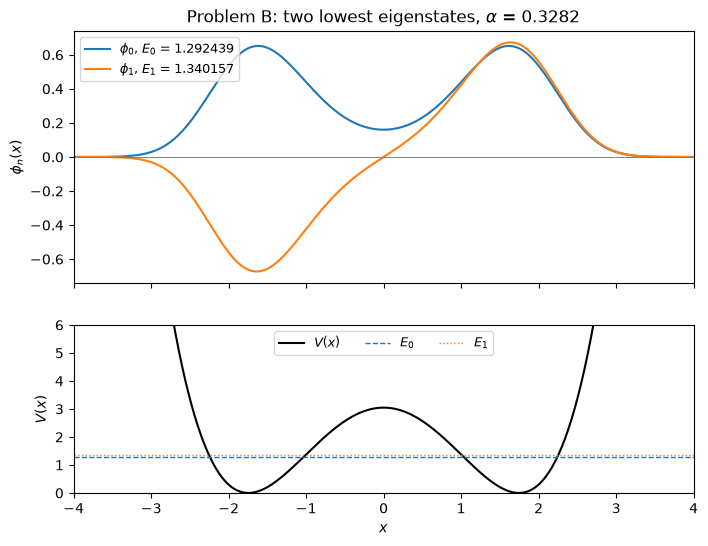

In [12]:
# B(iii): normalize, fix signs, two-panel plot

print("norms:", integrate(phi0**2), integrate(phi1**2), "  overlap <phi0|phi1>:", integrate(phi0 * phi1))
print("phi0 min:", phi0.min(), "  phi1 at x = +x_min:", np.interp(XMIN, x, phi1))

fig, (ax_phi, ax_V) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 2]})
ax_phi.plot(x, phi0, label=rf"$\phi_0$, $E_0$ = {E0:.6f}")
ax_phi.plot(x, phi1, label=rf"$\phi_1$, $E_1$ = {E1:.6f}")
ax_phi.axhline(0, color="gray", lw=0.7)
ax_phi.set(ylabel=r"$\phi_n(x)$", title=rf"Problem B: two lowest eigenstates, $\alpha$ = {ALPHA}")
ax_phi.legend(loc="upper left", fontsize=9)

ax_V.plot(x, V(x, ALPHA), color="black", label=r"$V(x)$")
ax_V.axhline(E0, color="C0", ls="--", lw=1, label=r"$E_0$")
ax_V.axhline(E1, color="C1", ls=":", lw=1, label=r"$E_1$")
ax_V.set(xlabel=r"$x$", ylabel=r"$V(x)$", xlim=(x[0], x[-1]), ylim=(0, 6))
ax_V.legend(loc="upper center", fontsize=9, ncol=3)
plt.show()

---
## Problem C [10 pts]: Harmonic-approximation energies

$$E_S=\frac{\int\psi_S^*\hat H\psi_S\,dx}{\int|\psi_S|^2dx},\qquad E_A=\frac{\int\psi_A^*\hat H\psi_A\,dx}{\int|\psi_A|^2dx}$$
Use **B's Hamiltonian matrix** and grid sums. **Keep the denominators**: $\psi_S,\psi_A$ are slightly unnormalized.

### Analysis of Problem C: Harmonic Approximation energies

**Trial states.** $\psi_S=\frac{\psi_++\psi_-}{\sqrt2}$ (even) and $\psi_A=\frac{\psi_+-\psi_-}{\sqrt2}$ (odd), evaluated with the **full** $\hat H$.

**Rayleigh quotient and variational principle.**
$$
E[\psi]=\frac{\int\psi^*\hat H\psi\,dx}{\int|\psi|^2dx}=\frac{\sum|c_n|^2E_n}{\sum|c_n|^2}\ \ge\ \text{lowest }E_n\text{ contained in }\psi .
$$
So $E_S\ge E_0$, and $E_A\ge E_1$ (odd $\psi_A$ has no even components). **Both signed errors are $\ge0$.** The error is second order in the wave-function error.

**Why keep the denominator ?**
$$
S=\int\psi_+\psi_-\,dx=e^{-\omega x_{\min}^2}=e^{-\omega/\alpha}\approx1.8\times10^{-4},\qquad
\int|\psi_S|^2=1+S,\quad\int|\psi_A|^2=1-S .
$$
Dropping them would shift $E_S,E_A$ by $\sim ES\approx2\times10^{-4}$: ten times B's grid error and $\sim5\%$ of the harmonic gap.

**On the grid** (B's matrix): $E_S=\dfrac{\boldsymbol\psi_S^TH\boldsymbol\psi_S}{\boldsymbol\psi_S^T\boldsymbol\psi_S}$, and likewise for $E_A$.

**Two-state (Rayleigh–Ritz) structure.** In the basis $\{\psi_+,\psi_-\}$:
$$
\mathsf H=\begin{pmatrix}h_d&h_o\\h_o&h_d\end{pmatrix},\quad
\mathsf S=\begin{pmatrix}1&S\\S&1\end{pmatrix}
\;\Rightarrow\;
E_S=\frac{h_d+h_o}{1+S},\quad E_A=\frac{h_d-h_o}{1-S},\quad
\Delta E_\text{harm}=\frac{2(Sh_d-h_o)}{1-S^2}.
$$
The gap depends only on $S$ and $h_o$, i.e. on the **barrier region** where $\psi_\pm$ overlap.

**Analytic values.** Using the exact expansion $V=4u^2+4\sqrt\alpha\,u^3+\alpha u^4$ ($u=x-x_{\min}$), $\hat H\psi_\pm=\frac\omega2\psi_\pm+(V-V_\pm)\psi_\pm$ and Gaussian moments ($\sigma^2=\frac1{2\omega}$):
$$
h_d=\sqrt2+\frac{3\alpha}{32},\qquad
h_o=S\Big[\frac\omega2-\frac3\alpha-\frac3\omega+\frac{3\alpha}{32}\Big],\qquad
\boxed{\Delta E_\text{harm}=\frac{6S}{1-S^2}\Big(\frac1\alpha+\frac1\omega\Big)}
$$
For $\alpha=0.3282$: $h_d\approx1.44498$, $h_o\approx-1.58\times10^{-3}$, $\Delta E_\text{harm}\approx3.69\times10^{-3}$, compared with $\Delta E\approx0.0477$ from B.

**Why the gap is much worse than the energies.**
1. **Error arithmetic:** $\Delta E_\text{harm}-\Delta E=\delta_A-\delta_S$ is divided by the tiny $\Delta E$, whereas the energy errors are divided by $E\approx1.3$.
2. **The gap is set by the barrier amplitude:**
$$
\Delta E=\frac{\phi_0(0)\,\phi_1'(0)}{2\int_0^\infty\phi_0\phi_1\,dx}\approx\phi_0(0)\,\phi_1'(0).
$$
3. **The parabola gets the barrier wrong:** $V_+(0)=4/\alpha\approx12.2$ versus $V(0)=1/\alpha\approx3.05$. The Gaussian decays too fast, leaving too little amplitude at $x=0$, so the gap is far too small.
4. **The energies are still decent:** they are dominated by the wells, where the fit is good, and the error is only second order.

### C(i) Compare energies
Compare $E_S, E_A, E_A-E_S$ with $E_0, E_1, \Delta E$. Report relative errors (e.g. $|E_S-E_0|/|E_0|$). Use the signed errors $E_S-E_0$ and $E_A-E_1$ to account for the gap error. Which is more accurate in relative terms: the energies or the gap?

In [13]:
# C(i): E_S, E_A and their errors

# Trial states from the harmonic approximation (left unnormalized, as defined)
psi_S = (psi_plus + psi_minus) / np.sqrt(2)
psi_A = (psi_plus - psi_minus) / np.sqrt(2)

def rayleigh(psi, H):
    """Energy estimate E[psi] = (dx psi^T H psi) / (dx psi^T psi), with B's grid Hamiltonian.
    The denominator is kept because psi_S, psi_A are not normalized (theory: norms 1 +/- S)."""
    return integrate(psi * (H @ psi)) / integrate(psi * psi)

E_S = rayleigh(psi_S, H)
E_A = rayleigh(psi_A, H)
DELTA_E_harm = E_A - E_S

# Signed and relative errors against Problem B (original grid)
delta_S, delta_A = E_S - E0, E_A - E1
rows = [("E_S vs E0", E_S, E0), ("E_A vs E1", E_A, E1), ("gap vs dE", DELTA_E_harm, DELTA_E)]
print(f"{'':<10} {'harmonic':>12} {'exact (B)':>12} {'signed err':>12} {'relative err':>13}")
for name, approx, exact in rows:
    print(f"{name:<10} {approx:>12.8f} {exact:>12.8f} {approx - exact:>12.3e} {abs(approx - exact) / abs(exact):>13.3e}")

print("\nvariational bounds hold (E_S >= E0, E_A >= E1):", E_S >= E0, E_A >= E1)
print(f"gap error = delta_A - delta_S: {DELTA_E_harm - DELTA_E:.6e} = {delta_A - delta_S:.6e}")

# Check against the analytic two-state results (theory C)
S = integrate(psi_plus * psi_minus)
h_d = integrate(psi_plus * (H @ psi_plus))
h_o = integrate(psi_plus * (H @ psi_minus))
print("\ncheck vs analytic formulas:")
print(f"  S       grid {S:.6e}   analytic e^(-omega/alpha)            {np.exp(-OMEGA / ALPHA):.6e}")
print(f"  h_d     grid {h_d:.8f}   analytic sqrt2 + 3 alpha/32          {np.sqrt(2) + 3 * ALPHA / 32:.8f}")
print(f"  h_o     grid {h_o:.6e}   analytic S[w/2 - 3/a - 3/w + 3a/32] "
      f"{S * (OMEGA / 2 - 3 / ALPHA - 3 / OMEGA + 3 * ALPHA / 32):.6e}")
print(f"  gap     grid {DELTA_E_harm:.6e}   analytic 6S(1/a + 1/w)/(1-S^2)      "
      f"{6 * S * (1 / ALPHA + 1 / OMEGA) / (1 - S**2):.6e}")
print(f"  norms   |psi_S|^2 = {integrate(psi_S**2):.8f} (1+S = {1 + S:.8f}),"
      f"  |psi_A|^2 = {integrate(psi_A**2):.8f} (1-S = {1 - S:.8f})")

               harmonic    exact (B)   signed err  relative err
E_S vs E0    1.44311023   1.29243917    1.507e-01     1.166e-01
E_A vs E1    1.44680056   1.34015701    1.066e-01     7.958e-02
gap vs dE    0.00369033   0.04771785   -4.403e-02     9.227e-01

variational bounds hold (E_S >= E0, E_A >= E1): True True
gap error = delta_A - delta_S: -4.402752e-02 = -4.402752e-02

check vs analytic formulas:
  S       grid 1.808218e-04   analytic e^(-omega/alpha)            1.808218e-04
  h_d     grid 1.44495501   analytic sqrt2 + 3 alpha/32          1.44498231
  h_o     grid -1.583883e-03   analytic S[w/2 - 3/a - 3/w + 3a/32] -1.583356e-03
  gap     grid 3.690325e-03   analytic 6S(1/a + 1/w)/(1-S^2)      3.689281e-03
  norms   |psi_S|^2 = 1.00018078 (1+S = 1.00018082),  |psi_A|^2 = 0.99981914 (1-S = 0.99981918)


**Answer (C(i)):**

+ **Both signed errors are positive**, as the variational principle requires: $E_S\ge E_0$, and $E_A\ge E_1$ because the odd $\psi_A$ contains no even states.
+ **Gap error from the signed errors:** $(E_A-E_S)-\Delta E=\delta_A-\delta_S=0.1066-0.1507=-0.0440$. $E_S$ overshoots by more than $E_A$, so the harmonic gap is far too small, about $13\times$ smaller than $\Delta E$.
+ **The energies are more accurate in relative terms** ($8$–$12\%$) than the gap ($92\%$). The errors $\delta_S$ and $\delta_A$ are similar in size, but their difference is divided by the small $\Delta E\approx0.048$ rather than by $E\approx1.3$.
+ **Check:** the grid results agree with the analytic two-state formulas ($S=e^{-\omega/\alpha}=1.81\times10^{-4}$, $\Delta E_\text{harm}=6S(1/\alpha+1/\omega)/(1-S^2)=3.69\times10^{-3}$) to $\sim10^{-6}$. Keeping the denominators $1\pm S$ matters: dropping them would shift each energy by $\sim2\times10^{-4}$.

### C(ii) Compare wave functions
Normalize $\psi_S$, then overlay $|\psi_S|$ and $|\phi_0|$ on a **logarithmic y-axis**. Mark a discrepancy in the barrier region and relate it to the limits of the local harmonic approximation. Use the energy errors from (i) to show why the gap's relative error can be large even when the energies' relative errors are small.

at x = 0:  |phi0| = 1.5995e-01,  |psi_S| = 1.8523e-02,  ratio phi0/psi_S = 8.64
inner turning points at x = +/-1.027;  V(0) = 3.047  vs  V_+(0) = 12.188


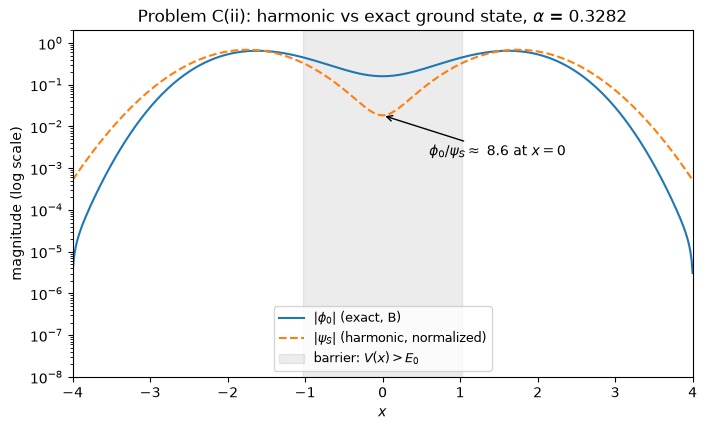

In [19]:
# C(ii): log-scale overlay

psi_S_n = normalize(psi_S)                              # normalized psi_S for the comparison
i0 = np.argmin(np.abs(x))                               # grid index of x = 0 (barrier centre)

# Classically forbidden barrier region for the ground state: V(x) > E0 between the wells
inner = (np.abs(x) < XMIN) & (V(x, ALPHA) > E0)
x_turn = np.abs(x[inner]).max()                          # inner turning point

print(f"at x = 0:  |phi0| = {abs(phi0[i0]):.4e},  |psi_S| = {abs(psi_S_n[i0]):.4e},"
      f"  ratio phi0/psi_S = {abs(phi0[i0] / psi_S_n[i0]):.2f}")
print(f"inner turning points at x = +/-{x_turn:.3f};  V(0) = {V(0.0, ALPHA):.3f}  vs  V_+(0) = {4 * XMIN**2:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(x, np.abs(phi0), label=r"$|\phi_0|$ (exact, B)")
ax.semilogy(x, np.abs(psi_S_n), "--", label=r"$|\psi_S|$ (harmonic, normalized)")
ax.axvspan(-x_turn, x_turn, color="gray", alpha=0.15, label=r"barrier: $V(x) > E_0$")
ax.annotate(rf"$\phi_0/\psi_S \approx$ {abs(phi0[i0] / psi_S_n[i0]):.1f} at $x=0$",
            xy=(0, abs(psi_S_n[i0])), xytext=(0.6, 2e-3),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set(xlabel=r"$x$", ylabel="magnitude (log scale)", xlim=(x[0], x[-1]), ylim=(1e-8, 2),
       title=rf"Problem C(ii): harmonic vs exact ground state, $\alpha$ = {ALPHA}")
ax.legend(loc="lower center", fontsize=9)
plt.show()

**Answer (C(ii)):**

+ $|\psi_S|\approx|\phi_0|$ in the wells, but in the barrier ($|x|<1.03$) $|\psi_S|$ is far too small: $\phi_0(0)/\psi_S(0)\approx8.6$ (marked).
+ $V_\pm$ fits only near the minima. At the centre the parabola gives $V_+(0)=4/\alpha=12.2$ versus the true $V(0)=1/\alpha=3.05$, so the Gaussian decays too fast in the barrier. (In the outer walls the true $V$ is steeper, so there $|\phi_0|<|\psi_S|$.)
+ the energies come mainly from the wells and are off by only $8$–$12\%$ ($\delta_S=0.151$, $\delta_A=0.107$). The gap is set by the barrier amplitude ($\Delta E\approx\phi_0(0)\phi_1'(0)$), and its error is the difference $\delta_A-\delta_S=-0.044$, which is comparable to $\Delta E=0.048$ itself. Since $E/\Delta E\approx27$, that gives a $92\%$ gap error.

---
## Problem D [10 pts]: Compare two evolution methods

Initial state for **both** methods: $\psi(x,0)=(\phi_0+\phi_1)/\sqrt2$, with B's signs. Set $T=2\pi/\Delta E$ and evolve to the **first time step at or after $T$**.

### D(i) From the eigenstates
$$\psi(x,t)=\frac{1}{\sqrt2}\left(e^{-iE_0t/\hbar}\phi_0(x)+e^{-iE_1t/\hbar}\phi_1(x)\right)$$
Show that $\langle x\rangle(t)=x_{01}\cos(\Delta E\,t/\hbar)$ with $x_{01}=\int\phi_0\,x\,\phi_1\,dx$, and hence $t_\text{tunnel}=\pi\hbar/\Delta E$. Identify where normalization and symmetry enter your derivation.

**Derivation (D(i)):**

### Analysis of Problem D: Comparing two evolution methods

**Setup.** Both methods start from
$$
\psi(x,0)=\frac{\phi_0(x)+\phi_1(x)}{\sqrt2},
$$
with B's signs ($\phi_0>0$, right lobe of $\phi_1>0$). The two add on the right and cancel on the left, so the state is localized in the **right** well. Set $T=2\pi/\Delta E$ and evolve $N_T=\lceil T/\epsilon\rceil$ steps (the first step at or after $T$).

**Normalization of the initial state.** With $\int\phi_m\phi_n\,dx=\delta_{mn}$ (true on the grid for B's eigenvectors):
$$
\int|\psi(x,0)|^2dx=\tfrac12\left(1+1+2\!\int\!\phi_0\phi_1\,dx\right)=1 .
$$

### D(i) Eigenstate evolution
Each eigenstate only acquires a phase:
$$
\psi(x,t)=\frac{1}{\sqrt2}\left(e^{-iE_0t}\phi_0+e^{-iE_1t}\phi_1\right).
$$
**Density** ($\phi_n$ real, since $H$ is real symmetric):
$$
|\psi(x,t)|^2=\tfrac12\left[\phi_0^2+\phi_1^2+2\phi_0\phi_1\cos(\Delta E\,t)\right],\qquad\Delta E=E_1-E_0 .
$$
**Normalization stays 1 at all times:** $\int|\psi|^2dx=\tfrac12[1+1+2\cos(\Delta E t)\!\int\!\phi_0\phi_1]=1$ by orthonormality, so no division is needed.

**Mean position:**
$$
\langle x\rangle(t)=\tfrac12\left[x_{00}+x_{11}+2x_{01}\cos(\Delta E\,t)\right],\qquad x_{mn}=\int\phi_m\,x\,\phi_n\,dx .
$$
**Symmetry:** $\phi_0^2$ and $\phi_1^2$ are even and $x$ is odd, so $x_{00}=x_{11}=0$. But $\phi_0\phi_1$ is odd, so $x\phi_0\phi_1$ is even and $x_{01}\ne0$. Therefore
$$
\boxed{\langle x\rangle(t)=x_{01}\cos(\Delta E\,t/\hbar)}
$$
- **Where each assumption enters.** The $\tfrac12$ comes from the $1/\sqrt2$ normalization. Orthonormality keeps $\int|\psi|^2=1$. Parity removes $x_{00}$ and $x_{11}$ and keeps $x_{01}$. On the grid this is exact (to rounding), because the grid is symmetric ($x_i=-x_{N_D-i}$) and B's eigenvectors are exactly even or odd.
- **Sign and size.** $x_{01}>0$ with B's signs, so $\langle x\rangle(0)=x_{01}$ (right well). It is somewhat less than $x_{\min}$ because both states leak into the barrier.
- **Tunneling time.** The first minimum is at $\cos(\Delta E t)=-1$, so $t_\text{tunnel}=\pi\hbar/\Delta E$ exactly. This is a pure sinusoid with no fast wiggles, because only two states are present.
- **Mirror image at $t_\text{tunnel}$.** $|\psi(x,t_\text{tunnel})|^2=\tfrac12(\phi_0-\phi_1)^2(x)=\tfrac12(\phi_0+\phi_1)^2(-x)=|\psi(-x,0)|^2$: the packet is the mirror image of the initial one, in the left well. At $T$ it is back to the initial density.
- The formula needs no time stepping, so it is exact at every $t$. It is evaluated at all steps (for the comparison) and at the 33 export times (`x_mean_eig`).

### D(ii) Path-integral evolution
The same code as A, with the two-state initial state. **If the path integral were exact**, it would reproduce D(i) exactly: the initial state contains only $\phi_0$ and $\phi_1$, so (unlike A's $\psi_+$) there are no higher states and no wiggles. **Any difference is therefore numerical error of the path-integral propagator.**

### D(iii) Where the methods can differ
$\Delta x\,\tilde K$ is only approximately $e^{-iH\epsilon}$ with B's $H$. Effectively, the path integral evolves with a slightly different operator, which has its own spectrum and eigenstates. Possible discrepancy patterns:

| Pattern in $\langle x\rangle_\text{PI}-\langle x\rangle_\text{eig}$ | Mechanism |
|---|---|
| Discrepancy growing roughly $\propto t$, zero crossings shifted | Path-integral gap $\Delta E_\text{PI}\ne\Delta E$, so the phase drifts: $\cos((\Delta E+\delta)t)-\cos(\Delta Et)\approx-\delta\,t\sin(\Delta Et)$ |
| Fast wiggles on the path-integral curve only | $(\phi_0+\phi_1)/\sqrt2$ is not exactly made of the path-integral eigenstates, so it leaks into higher ones and beats at higher-state gaps (compare A's wiggles) |
| Oscillation amplitude shrinks or the curve shifts | $\tilde K$ is not unitary, and renormalization each step changes the relative weights of the components |

The discrepancy is zero at $t=0$ by construction and accumulates with the number of steps, so expect it to be **largest late in the run**.

**Which parameter controls the error.**
- **$\Delta x$:** B's grid error is about $10^{-5}$ in energy (B.8), far too small to matter here.
- **$\epsilon$:** the short-time (midpoint) approximation. $\tilde K$ is time-symmetric ($\tilde K(-\epsilon)=\tilde K(\epsilon)^*$, and $\tilde K_{ij}=\tilde K_{ji}$), so odd-order errors cancel and the global error is **second order**, $\propto\epsilon^2$.

**Trap: you cannot shrink $\epsilon$ alone.** The kinetic phase $\kappa k^2$ ($k=|i-j|$, $\kappa=\Delta x^2/2\epsilon$) aliases at $k^*=\pi/\kappa$: there, neighboring phases differ by $2\pi$, so the sum acts like a fake stationary point, a "ghost path" jumping $k^*\Delta x$ in a single step. The method is only valid while that point lies outside the box:
$$
k^*>N_D\quad\Longleftrightarrow\quad 2\pi\epsilon>L\,\Delta x .
$$
Original grid: $2\pi\epsilon\approx0.154>L\Delta x\approx0.107$, OK. With $\epsilon/2$ and the same $\Delta x$: $0.077<0.107$, which **fails** (the evolution is garbage from the first steps).

**A valid targeted check.** Halve $\epsilon$ **and** $\Delta x$ together ($N_D=1200$, so $2\pi\epsilon=0.077>L\Delta x=0.053$). If the time step is the cause, the second-order prediction is that the maximum discrepancy shrinks by about $4\times$. If instead the discrepancy came from $\Delta x$, halving $\Delta x$ alone at fixed $\epsilon$ would reduce it.

### D(i) Eigenstate evolution

In [22]:
# D(i): <x>_eig(t) on the time grid, plus x_mean_eig at the 33 export times (n = 0, 64, ..., 2048)

# --- two-state initial state (B's signs: localized in the right well) and run length ---
psi0_D = (phi0 + phi1) / np.sqrt(2)
T_D = 2 * np.pi / DELTA_E                         # one full oscillation
NT_D = int(np.ceil(T_D / DELTAT))                 # first step at or after T
t_D = np.arange(NT_D + 1) * DELTAT

# --- matrix elements: normalization and parity checks (theory D(i)) ---
x00 = integrate(phi0 * x * phi0)
x11 = integrate(phi1 * x * phi1)
x01 = integrate(phi0 * x * phi1)
print(f"norm of psi(x,0) = {integrate(np.abs(psi0_D)**2):.12f},  <phi0|phi1> = {integrate(phi0 * phi1):.1e}")
print(f"x00 = {x00:.1e},  x11 = {x11:.1e}  (zero by parity),  x01 = {x01:.6f}")

# --- <x>(t) from the eigenstates: exact at any time, no time stepping ---
x_mean_eig_D = x01 * np.cos(DELTA_E * t_D)                  # every step, for the comparison
x_mean_eig = x01 * np.cos(DELTA_E * N_EXPORT * DELTAT)       # 33 export times, for results.json
t_tunnel_D = np.pi / DELTA_E

def density_eig(tt):
    """|psi(x,t)|^2 from eq. (11): each eigenstate only picks up a phase."""
    psi = (np.exp(-1j * E0 * tt) * phi0 + np.exp(-1j * E1 * tt) * phi1) / np.sqrt(2)
    return np.abs(psi)**2

# sanity check: the closed formula agrees with <x> computed directly from the density
for tt in (0.0, t_tunnel_D / 2, t_tunnel_D):
    print(f"t = {tt:7.3f}:  x01 cos(dE t) = {x01 * np.cos(DELTA_E * tt): .6f},  "
          f"dx sum x|psi|^2 = {integrate(x * density_eig(tt)): .6f}")
print(f"T = 2pi/dE = {T_D:.4f}  ->  {NT_D} steps (last t = {t_D[-1]:.4f});  t_tunnel = pi/dE = {t_tunnel_D:.4f}")

norm of psi(x,0) = 1.000000000000,  <phi0|phi1> = -9.5e-17
x00 = -7.7e-13,  x11 = 7.7e-13  (zero by parity),  x01 = 1.550021
t =   0.000:  x01 cos(dE t) =  1.550021,  dx sum x|psi|^2 =  1.550021
t =  32.918:  x01 cos(dE t) =  0.000000,  dx sum x|psi|^2 =  0.000000
t =  65.837:  x01 cos(dE t) = -1.550021,  dx sum x|psi|^2 = -1.550021
T = 2pi/dE = 131.6737  ->  5365 steps (last t = 131.6769);  t_tunnel = pi/dE = 65.8368


### D(ii) With the path integral
Reuse A's code with the two-state initial wave function above.

In [24]:
# Same path-integral code as A (K_tilde, evolve), only the initial state changes
prob_PI_D = evolve(psi0_D, K_tilde, DELTAX, NT_D)
x_mean_PI_D = DELTAX * (prob_PI_D @ x)

n_min = np.argmin(x_mean_PI_D)
print(f"<x>_PI(0) = {x_mean_PI_D[0]:.6f}   (x01 = {x01:.6f})")
print(f"path-integral minimum: t = {t_D[n_min]:.4f}, <x> = {x_mean_PI_D[n_min]:.6f}   "
      f"(eigenstates: t = {t_tunnel_D:.4f}, <x> = {-x01:.6f})")

<x>_PI(0) = 1.550021   (x01 = 1.550021)
path-integral minimum: t = 66.2925, <x> = -1.546070   (eigenstates: t = 65.8368, <x> = -1.550021)


### D(iii) Compare
- Overlay both $\langle x\rangle(t)$ curves and report $\max_{0\le n\epsilon\le T}\left|\langle x\rangle_\text{PI}(n\epsilon)-\langle x\rangle_\text{eig}(n\epsilon)\right|$.
- Overlay both probability densities at the steps nearest to $0,\ t_\text{tunnel},\ T$. Label the methods and the actual times.
- At the maximum discrepancy, report the time and both means.
- Identify a discrepancy pattern and a possible numerical cause. Propose one targeted check and predict its outcome (no extra run needed).
- *Optional:* animate both densities (.gif/.mp4). No extra points.

max |<x>_PI - <x>_eig| over 0 <= t <= T: 7.5377e-02
  at t = 128.7071:  <x>_PI = 1.459140,  <x>_eig = 1.534517
  discrepancy at t_tunnel:  7.714e-03,   at T: -6.582e-02


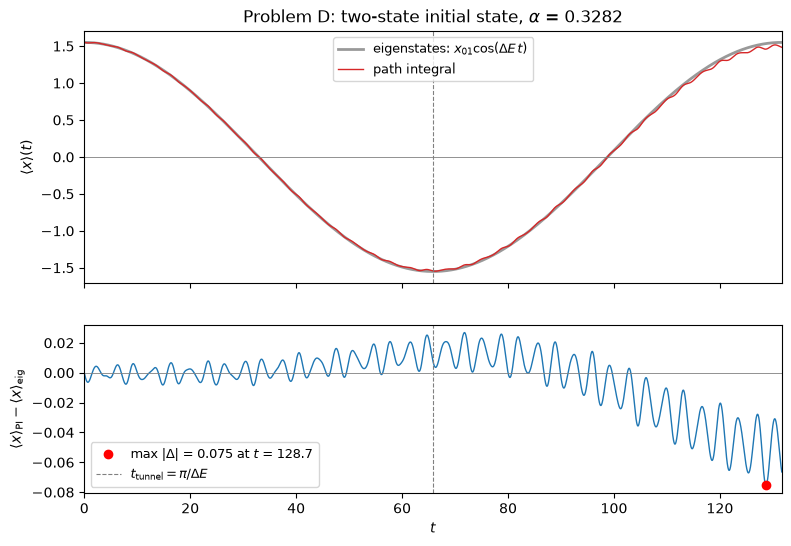

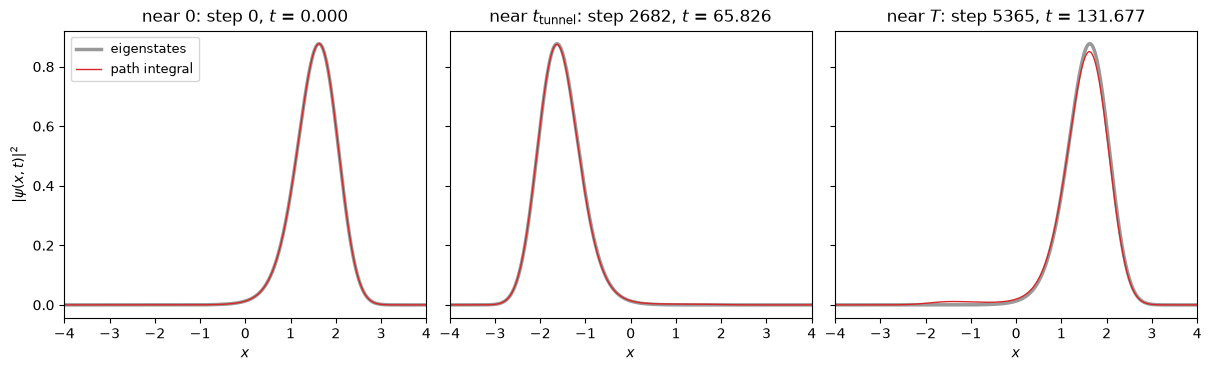

In [25]:
# D(iii): overlay <x> curves, max discrepancy, density snapshots

# --- maximum discrepancy, only over steps with n*eps <= T (eq. 12) ---
in_range = t_D <= T_D
diff = x_mean_PI_D - x_mean_eig_D
n_max = np.argmax(np.abs(diff[in_range]))
print(f"max |<x>_PI - <x>_eig| over 0 <= t <= T: {abs(diff[n_max]):.4e}")
print(f"  at t = {t_D[n_max]:.4f}:  <x>_PI = {x_mean_PI_D[n_max]:.6f},  <x>_eig = {x_mean_eig_D[n_max]:.6f}")
print(f"  discrepancy at t_tunnel: {diff[np.argmin(np.abs(t_D - t_tunnel_D))]: .3e},   at T: {diff[in_range][-1]: .3e}")

# --- figure 1: both <x>(t) curves and their difference ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.plot(t_D, x_mean_eig_D, lw=2, color="0.6", label=r"eigenstates: $x_{01}\cos(\Delta E\,t)$")
ax1.plot(t_D, x_mean_PI_D, lw=1, color="C3", label="path integral")
ax1.axvline(t_tunnel_D, color="gray", ls="--", lw=0.8)
ax1.axhline(0, color="gray", lw=0.6)
ax1.set(ylabel=r"$\langle x\rangle(t)$", title=rf"Problem D: two-state initial state, $\alpha$ = {ALPHA}")
ax1.legend(loc="upper center", fontsize=9)
ax2.plot(t_D, diff, color="C0", lw=1)
ax2.plot(t_D[n_max], diff[n_max], "o", color="red", label=rf"max $|\Delta|$ = {abs(diff[n_max]):.3f} at $t$ = {t_D[n_max]:.1f}")
ax2.axvline(t_tunnel_D, color="gray", ls="--", lw=0.8, label=r"$t_\mathrm{tunnel}=\pi/\Delta E$")
ax2.axhline(0, color="gray", lw=0.6)
ax2.set(xlabel=r"$t$", ylabel=r"$\langle x\rangle_\mathrm{PI}-\langle x\rangle_\mathrm{eig}$", xlim=(0, t_D[-1]))
ax2.legend(loc="lower left", fontsize=9)
plt.show()

# --- figure 2: densities at the steps nearest 0, t_tunnel, T ---
targets = [("0", 0.0), (r"t_\mathrm{tunnel}", t_tunnel_D), ("T", T_D)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, constrained_layout=True)
for ax, (name, tt) in zip(axes, targets):
    n = np.argmin(np.abs(t_D - tt))                       # nearest time step
    ax.plot(x, density_eig(t_D[n]), lw=2.5, color="0.6", label="eigenstates")
    ax.plot(x, prob_PI_D[n], lw=1, color="C3", label="path integral")
    ax.set(title=rf"near ${name}$: step {n}, $t$ = {t_D[n]:.3f}", xlabel=r"$x$", xlim=(x[0], x[-1]))
axes[0].set_ylabel(r"$|\psi(x,t)|^2$")
axes[0].legend(fontsize=9)
plt.show()

**Answer (D(iii)):**

+ **Max discrepancy:** $\max|\langle x\rangle_\text{PI}-\langle x\rangle_\text{eig}|=0.075$ at $t=128.71$ (near $T=131.67$), where $\langle x\rangle_\text{PI}=1.459$ and $\langle x\rangle_\text{eig}=1.535$.
+ **Pattern:** the difference is $0$ at $t=0$ and grows with time. It consists of fast wiggles (period $\approx3.5$) that appear only on the path-integral curve, plus a slow drift that becomes negative late in the run. The path-integral minimum is slightly late ($t=66.29$ vs. $\pi/\Delta E=65.84$), and at $T$ its density peak is lower, with a small remnant left in the left well. The eigenstate curve is a pure cosine, so all of this is numerical.
+ **Likely cause:** the finite time step $\epsilon$. $\Delta x\,\tilde K$ is only approximately $e^{-iH\epsilon}$, so the path integral has slightly different eigenstates and energies than B's $H$. The two-state initial state therefore leaks into higher states (the fast wiggles, at a higher-state gap $\approx E_2-E_1$), and the phase and amplitude of the slow oscillation drift. These errors accumulate step by step, which is why the discrepancy is largest near $T$.
+ **Targeted check:** halve $\epsilon$ **and** $\Delta x$ together ($\epsilon=\pi/256$, $N_D=1200$). Halving $\epsilon$ alone would violate $2\pi\epsilon>L\Delta x$ and break the kernel. **Prediction:** the short-time kernel is time-symmetric, so its error is second order, and the max discrepancy should drop by about $4\times$ (to $\approx0.019$).

---
## Autograded results: `results.json`
Run this **last**, once every variable exists. Upload `results.json` together with the source files to "Assignment 2 Code".

| Field | Contents |
|---|---|
| `tsn`, `alpha` | your TSN (string) and $\alpha$ |
| `x_mean_pi` | A: $\langle x\rangle$ at $n=0,64,\dots,2048$ (33 values), starting from $\psi_+$ |
| `t_tunnel` | A: measured $t_\text{tunnel}$ |
| `E0`, `E1` | B: original grid |
| `phi0`, `phi1` | B: 601 values each, normalized, B's signs |
| `E_S`, `E_A` | C |
| `x_mean_eig` | D(i): at the same 33 times |

In [28]:
results = {
    "tsn": TSN,
    "alpha": ALPHA,
    "x_mean_pi": x_mean_pi.tolist(),
    "t_tunnel": float(t_tunnel),
    "E0": float(E0), "E1": float(E1),
    "phi0": phi0.tolist(), "phi1": phi1.tolist(),
    "E_S": float(E_S), "E_A": float(E_A),
    "x_mean_eig": x_mean_eig.tolist(),
}
with open("results.json", "w") as f:
    json.dump(results, f)
print("wrote results.json")

wrote results.json


---
## AI use appendix
*(Required by the syllabus.)* List the tools you used and what for, your prompts (or a conversation link), and what the tools got wrong and how you caught it.